# **EDA cơ bản cho dữ liệu ảnh nghệ thuật**

- Nguồn dữ liệu: Unplash
- Kỹ thuật: cào qua API https://unsplash.com/developers do unsplash cung cấp
- Thời gian thực hiện: cào trong 3 giờ (mỗi giờ gửi 45/50 request với kỳ vọng từ 500-1350 ảnh/giờ)

### Từ điển dữ liệu
| Thuộc tính | Ý nghĩa |
|--|--|
| `image_id` | Mã định danh duy nhất của ảnh trên Unsplash |
| `query_label`| Nhãn phân loại đại diện của ảnh | 
| `description` | Mô tả của ảnh do người chụp lựa chọn viết |
| `alt_description`| Mô tả thay thế cho ảnh khi ảnh không thể hiển thị |
| `created_at` | Ngày đăng trên Unsplash |
| `likes` | Lượt thích của ảnh trên Unsplash |
| `width` | Chiều rộng của ảnh, tính bằng pixel |
| `height` | Chiều cao của ảnh, tính bằng pixel |
| `color` | Mã hex lưu màu sắc chủ đạo của ảnh do Unplash tự gán |
| `user_name` | Tên người đăng | 
| `user_url`| url dẫn đến hồ sơ của người đăng trên Unsplash |



**Nhận xét**
- Định hướng rõ ràng của bộ dữ liệu là thu thập dữ liệu liên quan đến nghệ thuật qua các keyword tìm kiếm: "architecture", "art", "design", "drawing", "heritage", "illustration", "painting", "pattern", "portrait", "sculpture"
- Một ảnh trên Unsplash tuy hiển thị có nhiều nhãn nhưng trong file json lưu thông tin một ảnh lại không lưu trường phân loại đó, nên thực hiện phân loại dựa trên nhãn tìm kiếm ảnh trước khi tải do đó chắc chắn sẽ có trường hợp nhãn đó là không hoàn toàn đúng với ngữ cảnh thật sự của bức ảnh.
- Đối với thông tin người đăng, tuy trong thông tin ảnh có hiển thị đầy đủ các trường nhưng do chưa xác định đủ bài toán thực hiện nên lưu gây năng file dữ liệu / dư thừa cột dữ liệu. Thay vào đó lưu đường dẫn và thực hiện cào thêm dữ liệu người dùng nếu cần.

$\rightarrow$ Bộ dữ liệu định hướng ảnh nghệ thuật chung chung

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [64]:
data = pd.read_csv("Data/unsplash_metadata.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5771 entries, 0 to 5770
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   image_id         5771 non-null   str  
 1   query_label      5771 non-null   str  
 2   description      3740 non-null   str  
 3   alt_description  5750 non-null   str  
 4   created_at       5771 non-null   str  
 5   likes            5771 non-null   int64
 6   width            5771 non-null   int64
 7   height           5771 non-null   int64
 8   color            5771 non-null   str  
 9   user_name        5771 non-null   str  
 10  user_url         5771 non-null   str  
dtypes: int64(3), str(8)
memory usage: 1.7 MB


- 2 cột có khuyết dữ liệu: `description` và `alt_description` vì đây là dữ liệu do người dùng tạo.
- `description` cho thấy tỷ lệ khuyết dữ liệu cao nhất: 35.2%.
- `alt_description` cho thấy tỷ lệ khuyết dữ liệu chỉ: 0.36%.

> Tuy nhiên `description` chỉ đem đến thêm metadata mô tả ngữ cảnh bức ảnh trong khi `alt_description` lại mô tả trực tiếp nội dung bức ảnh.
> `alt_description` đem lại ý nghĩa lớn hơn khi phân tích ngắn gọn cái thật sự có trong ảnh.

In [65]:
# Chuyển đổi kiểu dữ liệu
data[['query_label', 'user_name']] = data[['query_label', 'user_name']].astype('category')
data["created_at"] = pd.to_datetime(data["created_at"], utc=True)

,count,percent
query_label,,
portrait,671,11.63
architecture,663,11.49
sculpture,630,10.92
design,618,10.71
drawing,608,10.54
heritage,563,9.76
pattern,525,9.10
painting,524,9.08
illustration,507,8.79


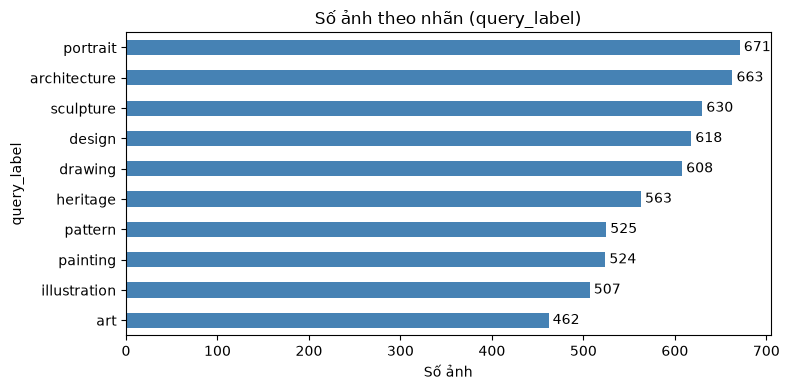

In [66]:
# Phân phối theo nhãn
label_counts = data["query_label"].value_counts()
display(label_counts.to_frame("count").assign(percent = lambda d: (d["count"] / len(data) * 100).round(2)))

fig, ax = plt.subplots(figsize=(8, 4))
label_counts.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Số ảnh theo nhãn (query_label)")
ax.set_xlabel("Số ảnh")
for i, v in enumerate(label_counts.sort_values().values):
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.show()

- Số lượng nhãn chiếm tương đối cân bằng, không có lệch nặng về một nhãn ảnh nào (do quá trình cào dữ liệu, đã lọc đi các ảnh trùng lặp nên số lượng ảnh tuy lập trình là lấy cùng số lượng mẫu mỗi lần nhưng đã bị loại bớt) $\rightarrow$ Phân phối ảnh tự nhiên khi các ảnh với nhãn tổng quát, không đem lại nhiều ảnh hưởng thì số lượng ảnh tìm kiếm trong nhãn đó bị giới hạn.
- Tuy nhiên ý nghĩa giữa các nhãn có phần giao nhau chứ không tách biệt hoàn toàn nên có thể tồn tại các ảnh vừa đồng thời thuộc từ 2 nhãn trở lên.
> Phân phối tương đối cân bằng, không ảnh hưởng

count     5771.000000
mean       588.313291
std       1421.291022
min          0.000000
25%          7.000000
50%         91.000000
75%        523.000000
max      24788.000000
Name: likes, dtype: float64

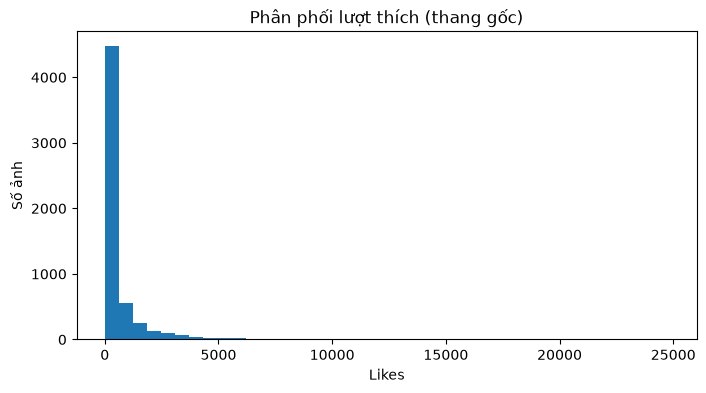

In [67]:
# Phân phối theo lượt thích
likes = pd.to_numeric(data["likes"], errors="coerce") if "likes" in data.columns else pd.Series(dtype=float)

fig, axes = plt.subplots(1, 1, figsize=(8, 4))
axes.hist(likes.dropna(), bins=40)
axes.set_title("Phân phối lượt thích (thang gốc)")
axes.set_xlabel("Likes")
axes.set_ylabel("Số ảnh")

data["likes"].describe()

- Hầu hết ảnh (75%) có dưới 523 like trong khi ảnh có số lượt thích lớn nhất là 24788, tạo ra các ngoại lai trong ảnh khi có những ảnh có tương tác tốt hơn (nhiều like hơn) trong khi phần đông gần như không có tương tác. Vì lượt thích bị ảnh hưởng bởi các yếu tố: thời gian đăng, thời gian cào dữ liệu, độ nổi tiếng của người dùng, thuật toán gợi ý đề xuất...

$\rightarrow$ Không nên dựa vào lượt thích để đánh giá chất lượng về mặt kỹ thuật của một ảnh. Còn về mặt độ ảnh hưởng của ảnh đó khó có thể đánh giá do mẫu dữ liệu nhỏ (chỉ hơn 5700 ảnh).

Số ảnh có kích thước hợp lệ: 5,771/5,771 (100.00%)


,width,height,aspect_ratio,resolution_mp
count,5771.000,5771.000,5771.000,5771.000
mean,4371.601,4396.010,1.069,20.399
std,1640.952,1640.674,0.404,15.654
min,1440.000,1277.000,0.352,2.037
25%,3250.000,3274.500,0.667,11.644
50%,4000.000,4000.000,0.829,17.916
75%,5405.500,5354.000,1.500,24.000
90%,6016.000,6016.000,1.503,34.461
95%,7407.500,7474.500,1.645,45.018
max,16384.000,16384.000,3.179,209.814


,count,percent
orientation,,
Portrait (dọc),2981,51.65
Landscape (ngang),2683,46.49
Square (vuông),107,1.85


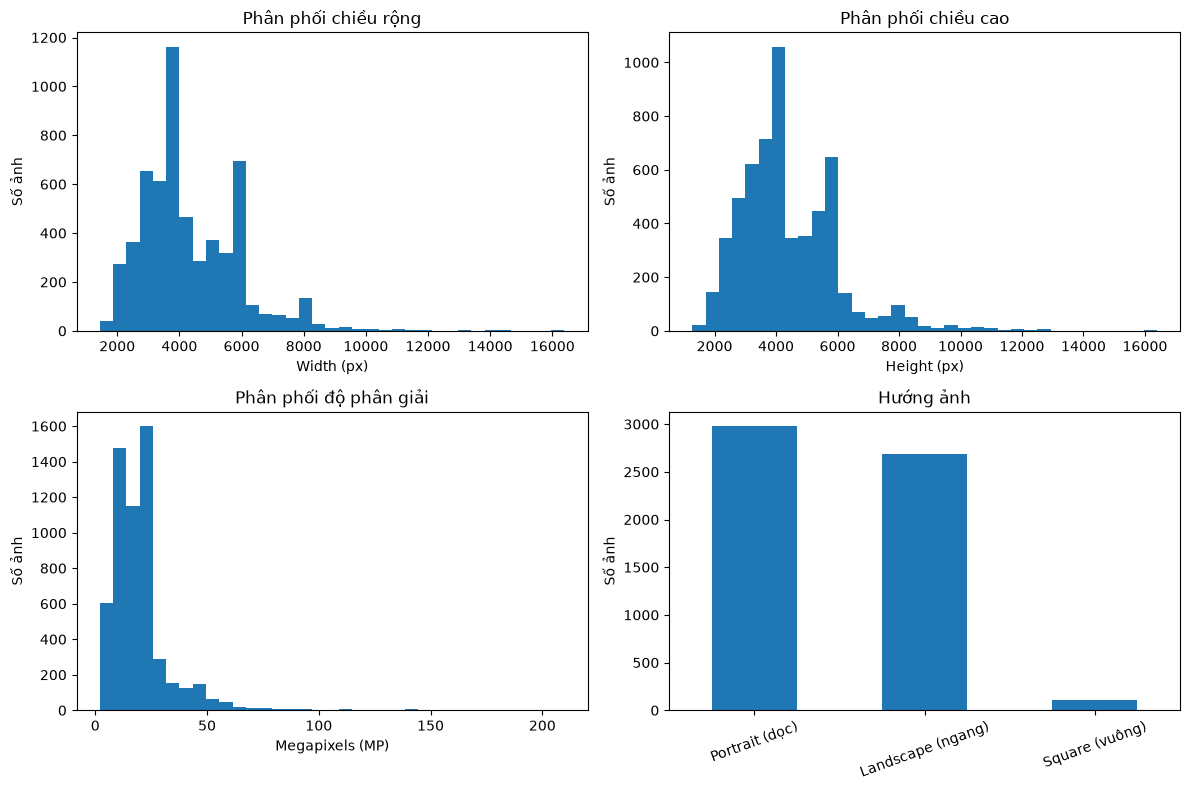

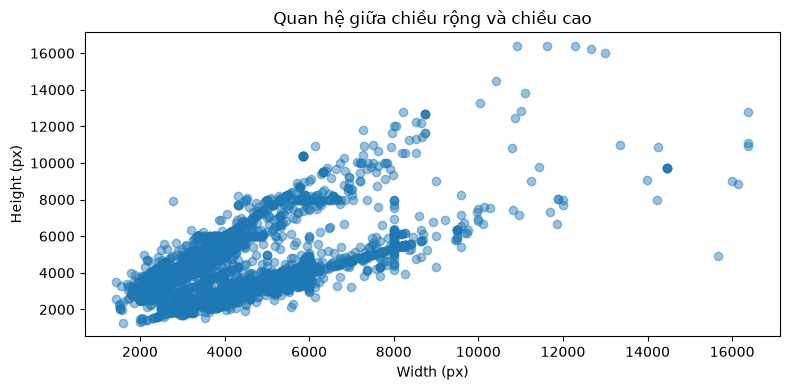

In [68]:
# Thông số kỹ thuật của ảnh
img = data.copy()
img["width"] = pd.to_numeric(img["width"], errors="coerce")
img["height"] = pd.to_numeric(img["height"], errors="coerce")
valid_dims = img["width"].gt(0) & img["height"].gt(0)
img["resolution_mp"] = (img["width"] * img["height"]) / 1_000_000
img["aspect_ratio"] = img["width"] / img["height"]
img["orientation"] = np.select(
    [img["width"] > img["height"], img["width"] < img["height"]],
    ["Landscape (ngang)", "Portrait (dọc)"],
    default="Square (vuông)"
)

print(f"Số ảnh có kích thước hợp lệ: {valid_dims.sum():,}/{len(img):,} "
        f"({valid_dims.mean() * 100:.2f}%)")
display(img.loc[valid_dims, ["width", "height", "aspect_ratio", "resolution_mp"]]
        .describe(percentiles=[.25, .5, .75, .90, .95]).round(3))

orientation_counts = img.loc[valid_dims, "orientation"].value_counts()
display(orientation_counts.to_frame("count").assign(
    percent=lambda x: (x["count"] / x["count"].sum() * 100).round(2)
))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(img.loc[valid_dims, "width"], bins=35)
axes[0, 0].set_title("Phân phối chiều rộng")
axes[0, 0].set_xlabel("Width (px)")
axes[0, 0].set_ylabel("Số ảnh")

axes[0, 1].hist(img.loc[valid_dims, "height"], bins=35)
axes[0, 1].set_title("Phân phối chiều cao")
axes[0, 1].set_xlabel("Height (px)")
axes[0, 1].set_ylabel("Số ảnh")

axes[1, 0].hist(img.loc[valid_dims, "resolution_mp"], bins=35)
axes[1, 0].set_title("Phân phối độ phân giải")
axes[1, 0].set_xlabel("Megapixels (MP)")
axes[1, 0].set_ylabel("Số ảnh")

orientation_counts.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Hướng ảnh")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Số ảnh")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(img.loc[valid_dims, "width"], img.loc[valid_dims, "height"], alpha=.45)
ax.set_title("Quan hệ giữa chiều rộng và chiều cao")
ax.set_xlabel("Width (px)")
ax.set_ylabel("Height (px)")
plt.tight_layout()
plt.show()

- Độ phân giải ảnh lệch phải mạnh với trung bình các ảnh đều đạt 20MP (mean) là một mức phân giải rất tốt khi giữ đủ chi tiết ảnh.
- Số lượng ảnh thuộc 2 hướng dọc và ngang gần như bằng nhau, phù hợp để đánh giá với đủ hướng ảnh, tuy vẫn có ảnh ở dạng vuông nhưng lại chiếm tỷ lệ nhỏ.
- Quan hệ giữa width và height có tính chất tuyến tính theo 2 đường thẳng tuyến tính khác nhau (tương đương với 2 hướng ảnh: ảnh dọc và ảnh ngang).

> Trong bài toán xử lý ảnh, độ phân giải ảnh cùng kích thước ảnh này vẫn cho phép cắt hình sao cho phù hợp nên lệch trong phân phối theo hướng ảnh là không ảnh hưởng vì hầu hết ảnh đều có kích thước lớn, độ phân giải từ trung bình đến cao vẫn phù hợp cho mạng neuron từ cơ bản đến phức tạp trong máy học